In [1]:
from collections import Counter
import pandas as pd
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import sklearn
from sklearn.ensemble import RandomForestClassifier
import shap

data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage5_deybe\296×87.xlsx")
X = data.iloc[:, 3:]
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

(296, 87)

In [2]:

def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(int(df.at[index, 'number']))
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage5_deybe\benchmark5.xlsx"
reported_structures = extract_numbers(file_path)

In [3]:
pca = PCA(n_components= 0.3, random_state=42)
new_data = pca.fit_transform(X)
print(new_data.shape)
ratios = pca.explained_variance_ratio_
components = pca.components_
X = pd.DataFrame(X)

components_df = pd.DataFrame(
    components,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(components.shape[0])]
)

output_file = "pca_components.xlsx"
components_df.to_excel(output_file, index=True)


i = 5
kmeans_plus = KMeans(n_clusters=i, init='random', n_init= 'auto', tol=1e-6, algorithm="lloyd", max_iter = 1000, random_state=42)
kmeans_plus.fit(new_data)
labels = kmeans_plus.labels_
print(f"Silhouette score: {silhouette_score(new_data, labels):.2f}")
print(f"Calinski-Harabasz score: {calinski_harabasz_score(new_data, labels):.2f}")

label_1 = []
for num  in  reported_structures:
        label = labels[num-1]
        label_1.append(int(label))
print(label_1)
df = pd.DataFrame(labels)
df.to_excel("kmeans_result.xlsx")

data[f'cluster_{i}'] = labels

print(f"\nNumber of clusters k={i}:")


for cluster in range(i):

    cluster_samples = data[data[f'cluster_{i}'] == cluster]
            # print(cluster_samples)

    total_in_cluster = len(cluster_samples)
    print(total_in_cluster)

    reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])

    print(f"Cluster {cluster}: {reported_in_cluster}/{total_in_cluster} "
                f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")

(296, 2)
Silhouette score: 0.43
Calinski-Harabasz score: 423.87
[4, 4, 4, 3, 4, 2, 3, 2, 2, 3, 4, 3, 1, 4, 4]

Number of clusters k=5:
41
Cluster 0: 0/41 (Reported ratio: 0.00%)
50
Cluster 1: 1/50 (Reported ratio: 2.00%)
67
Cluster 2: 3/67 (Reported ratio: 4.48%)
63
Cluster 3: 4/63 (Reported ratio: 6.35%)
75
Cluster 4: 7/75 (Reported ratio: 9.33%)


In [4]:


clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(new_data, labels)

print(f"Training fidelity accuracy: {clf.score(new_data, labels):.2f}")

# ============================================================


# ============================================================
from collections import Counter
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)


class_counts = Counter(labels)
min_class_count = min(class_counts.values())
n_splits = min(5, min_class_count)

if n_splits < 2:
    raise ValueError(
        f" {min_class_count} ， 2 。"
    )

print("\n========== RF surrogate classifier fidelity evaluation ==========")
print("Samples per cluster:", dict(sorted(class_counts.items())))
print(f" Stratified {n_splits}-fold cross-validation")


rf_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Macro-F1": "f1_macro",
    "Balanced Accuracy": "balanced_accuracy"
}

cv_results = cross_validate(
    rf_cv,
    new_data,
    labels,
    cv=StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42),
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

print("\nCross-validation results (mean ± std):")
for metric_name in scoring:
    scores = cv_results[f"test_{metric_name}"]
    print(f"{metric_name}: {scores.mean():.4f} ± {scores.std(ddof=1):.4f}")


cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
oof_pred = cross_val_predict(
    rf_cv,
    new_data,
    labels,
    cv=cv,
    n_jobs=-1
)

oof_acc = accuracy_score(labels, oof_pred)
oof_macro_f1 = f1_score(labels, oof_pred, average="macro")
oof_bal_acc = balanced_accuracy_score(labels, oof_pred)

print("\nOverall OOF evaluation:")
print(f"OOF Accuracy:          {oof_acc:.4f}")
print(f"OOF Macro-F1:          {oof_macro_f1:.4f}")
print(f"OOF Balanced Accuracy: {oof_bal_acc:.4f}")

print("\nClassification report:")
print(classification_report(labels, oof_pred, digits=4, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(labels, oof_pred))






Training fidelity accuracy: 1.00

========== RF surrogate classifier fidelity evaluation ==========
Samples per cluster: {np.int32(0): 41, np.int32(1): 50, np.int32(2): 67, np.int32(3): 63, np.int32(4): 75}
 Stratified 5-fold cross-validation

Cross-validation results (mean ± std):
Accuracy: 0.9628 ± 0.0142
Macro-F1: 0.9608 ± 0.0146
Balanced Accuracy: 0.9608 ± 0.0127

Overall OOF evaluation:
OOF Accuracy:          0.9628
OOF Macro-F1:          0.9610
OOF Balanced Accuracy: 0.9609

Classification report:
              precision    recall  f1-score   support

           0     0.9286    0.9512    0.9398        41
           1     0.9592    0.9400    0.9495        50
           2     1.0000    0.9851    0.9925        67
           3     0.9839    0.9683    0.9760        63
           4     0.9351    0.9600    0.9474        75

    accuracy                         0.9628       296
   macro avg     0.9613    0.9609    0.9610       296
weighted avg     0.9633    0.9628    0.9630       296

Co

In [5]:


explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(new_data)
print(shap_values.shape)

(296, 2, 5)


正在生成 Cluster 1 的全局重要性分析并保存为 PDF...


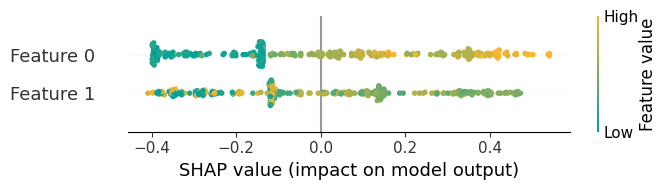

保存成功：Cluster1_Summary_Plot.pdf


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import shap
import matplotlib.colors as mcolors


shap_array = np.array(shap_values)




cluster_4_values = shap_array[:, :new_data.shape[1], 4]


fixed_width = 7
fixed_height = 2



custom_colors = ["#00A29A", "#F8B62D"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_shap_cmap", custom_colors)
# --------------------------------------------------------


print('\u6b63\u5728\u751f\u6210 Cluster 1 \u7684\u5168\u5c40\u91cd\u8981\u6027\u5206\u6790\u5e76\u4fdd\u5b58\u4e3a PDF...')


plt.figure(facecolor='white')


shap.summary_plot(
    cluster_4_values,
    new_data,
    plot_size=(fixed_width, fixed_height),
    cmap=custom_cmap,
    show=False
)

fig = plt.gcf()
fig.set_facecolor('white')



plt.savefig("Cluster0_Summary_Plot.pdf", bbox_inches='tight', facecolor='white')


plt.show()

print('\u4fdd\u5b58\u6210\u529f\uff1aCluster1_Summary_Plot.pdf')